<a href="https://colab.research.google.com/github/HarshMittal03/data-analytics-projects/blob/main/capstone_project_1(Loan_approval)_harsh_mittal_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone project 1 (Loan approval database)

**Import all the needed liberaries**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


Upload data set

In [ ]:
df=pd.read_csv("/content/loan_sanction_test.csv")

# Task 1: Data Exploration

Understand Data set
(structure, missing values, summary stats)

In [ ]:
df.head()


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,LP001015,Male,Yes,0,Graduate,No,5720,0,110.0,360.0,1.0,Urban
1,LP001022,Male,Yes,1,Graduate,No,3076,1500,126.0,360.0,1.0,Urban
2,LP001031,Male,Yes,2,Graduate,No,5000,1800,208.0,360.0,1.0,Urban
3,LP001035,Male,Yes,2,Graduate,No,2340,2546,100.0,360.0,NaN,Urban
4,LP001051,Male,No,0,Not Graduate,No,3276,0,78.0,360.0,1.0,Urban


In [ ]:
df.tail()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
362,LP002971,Male,Yes,3+,Not Graduate,Yes,4009,1777,113.0,360.0,1.0,Urban
363,LP002975,Male,Yes,0,Graduate,No,4158,709,115.0,360.0,1.0,Urban
364,LP002980,Male,No,0,Graduate,No,3250,1993,126.0,360.0,NaN,Semiurban
365,LP002986,Male,Yes,0,Graduate,No,5000,2393,158.0,360.0,1.0,Rural
366,LP002989,Male,No,0,Graduate,Yes,9200,0,98.0,180.0,1.0,Rural


In [ ]:
df.shape

(367, 12)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 367 entries, 0 to 366
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            367 non-null    object 
 1   Gender             356 non-null    object 
 2   Married            367 non-null    object 
 3   Dependents         357 non-null    object 
 4   Education          367 non-null    object 
 5   Self_Employed      344 non-null    object 
 6   ApplicantIncome    367 non-null    int64  
 7   CoapplicantIncome  367 non-null    int64  
 8   LoanAmount         362 non-null    float64
 9   Loan_Amount_Term   361 non-null    float64
 10  Credit_History     338 non-null    float64
 11  Property_Area      367 non-null    object 
dtypes: float64(3), int64(2), object(7)
memory usage: 34.5+ KB


In [ ]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area'],
      dtype='object')

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
Loan_ID,0
Gender,11
Married,0
Dependents,10
Education,0
Self_Employed,23
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,5
Loan_Amount_Term,6


In [ ]:
df.isnull().sum()/len(df)*100

,0
Loan_ID,0.000000
Gender,2.997275
Married,0.000000
Dependents,2.724796
Education,0.000000
Self_Employed,6.267030
ApplicantIncome,0.000000
CoapplicantIncome,0.000000
LoanAmount,1.362398
Loan_Amount_Term,1.634877


In [ ]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct}).query("missing_count > 0")

,missing_count,missing_pct
Gender,11,3.00
Dependents,10,2.72
Self_Employed,23,6.27
LoanAmount,5,1.36
Loan_Amount_Term,6,1.63
Credit_History,29,7.90


In [ ]:
data = df.copy()

num_cols = ["LoanAmount", "Loan_Amount_Term", "Credit_History"]
cat_cols = ["Gender", "Married", "Dependents", "Self_Employed"]

for col in num_cols:
    data[col] = data[col].fillna(data[col].median())

for col in cat_cols:
    data[col] = data[col].fillna(data[col].mode()[0])

print("missing values:", data.isnull().sum().sum())

missing values: 0


In [ ]:
data.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,367.000000,367.000000,367.000000,367.000000,367.000000
mean,4805.599455,1569.577657,135.980926,342.822888,0.839237
std,4910.685399,2334.232099,60.959739,64.658402,0.367814
min,0.000000,0.000000,28.000000,6.000000,0.000000
25%,2864.000000,0.000000,101.000000,360.000000,1.000000
50%,3786.000000,1025.000000,125.000000,360.000000,1.000000
75%,5060.000000,2430.500000,157.500000,360.000000,1.000000
max,72529.000000,24000.000000,550.000000,480.000000,1.000000


In [ ]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
ApplicantIncome,367.0,4805.599455,4910.685399,0.0,2864.0,3786.0,5060.0,72529.0
CoapplicantIncome,367.0,1569.577657,2334.232099,0.0,0.0,1025.0,2430.5,24000.0
LoanAmount,367.0,135.980926,60.959739,28.0,101.0,125.0,157.5,550.0
Loan_Amount_Term,367.0,342.822888,64.658402,6.0,360.0,360.0,360.0,480.0
Credit_History,367.0,0.839237,0.367814,0.0,1.0,1.0,1.0,1.0


In [ ]:
df.describe(include='object')

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area
count,367,356,367,357,367,344,367
unique,367,2,2,4,2,2,3
top,LP002989,Male,Yes,0,Graduate,No,Urban
freq,1,286,233,200,283,307,140


In [ ]:
df.describe(include='object').T

,count,unique,top,freq
Loan_ID,367,367,LP002989,1
Gender,356,2,Male,286
Married,367,2,Yes,233
Dependents,357,4,0,200
Education,367,2,Graduate,283
Self_Employed,344,2,No,307
Property_Area,367,3,Urban,140


# Task 1 outcomes

The dataset has 367 applicants and 12 columns

Missing values are  in `

Gender	11	3.00

Dependents	10	2.72

Self_Employed	23	6.27

LoanAmount	5	1.36

Loan_Amount_Term	6	1.63

Credit_History	29	7.90

they affect the data outcome so numerical data type columns filled with median and categorical data type columns filled with Mode

Applicant Income  and Co applicant Income  have no missing values
Both columns contain outlier but if we remove that affect the outcome

# Task 2: Data Visualization

**2.1 Univariate Analysis**
Explore the distribution of numeric columns using the  visualizations

**Histograms: Plot the frequency distribution of key numeric variables.**

**1.Distribution Applicant Income**

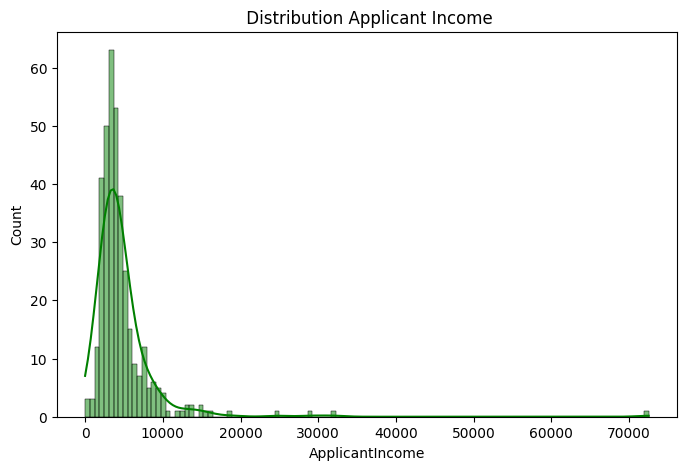

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data["ApplicantIncome"], kde=True,  color="green")
plt.title(" Distribution Applicant Income")
plt.show()

**2.Distribution of co Applicant Income**

---



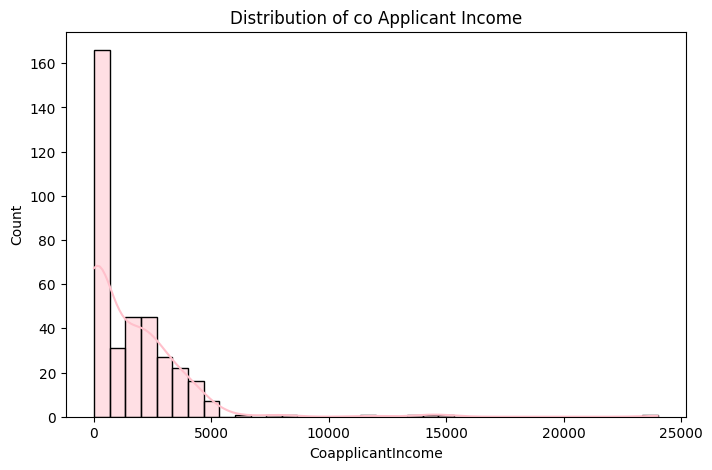

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data["CoapplicantIncome"], kde=True, color="pink")
plt.title("Distribution of co Applicant Income")
plt.show()

**3.Distribution of Loan Amount**

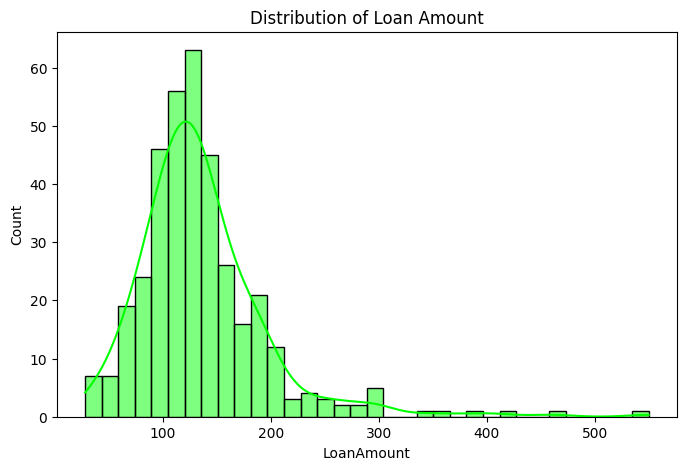

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data["LoanAmount"], kde=True, color="lime")
plt.title("Distribution of Loan Amount")
plt.show()

**4.Distribution of Loan Amount Term**

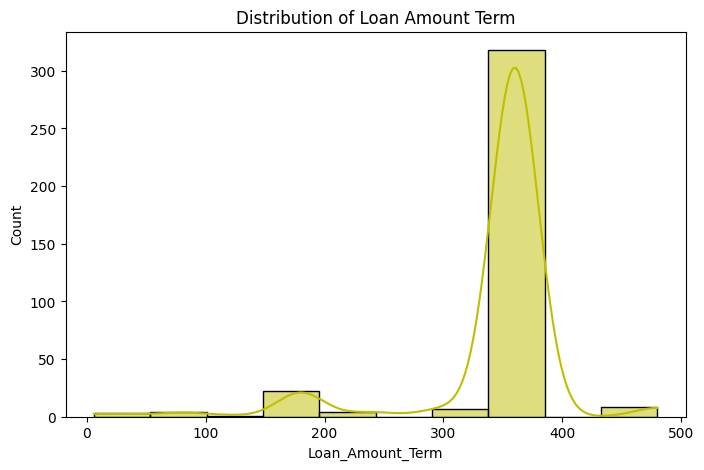

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data["Loan_Amount_Term"], kde=True, color="y")
plt.title("Distribution of Loan Amount Term")
plt.show()

**5.Distribution of Credit History**

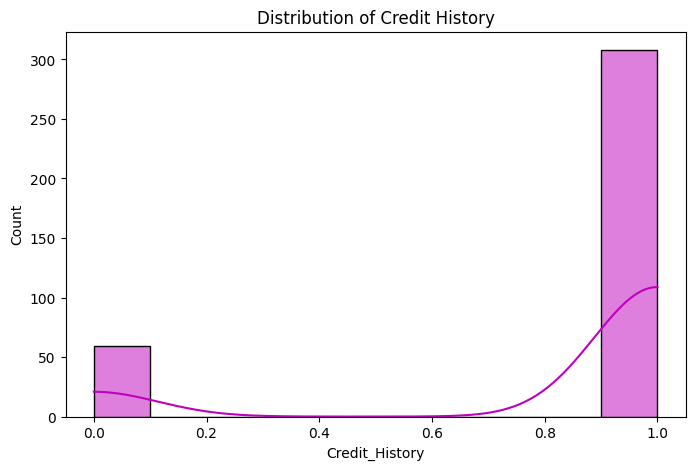

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data["Credit_History"], kde=True, color="m")
plt.title("Distribution of Credit History")
plt.show()

# Outcomes of Task 2.1

1. Applicant Income is right skewed distribution most values are under 10000
2. co Applicant Income  Extreme right skewed distribution highest peak at 0 most applicant falls under 5000
3. Loan amount Moderated right skewed distribution most common between 100-150
4. Loan amount Term massive peak at 350-360
5. credit history has more value of 1 (Yes) rather than 0(No)

**2.2 Box Plots: Identify potential outliers and visualize the spread of data.**

1. Box plot of Applicant Income

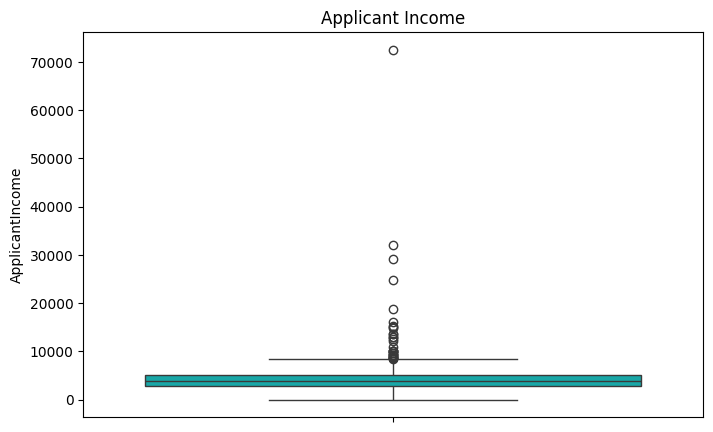

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(y=data["ApplicantIncome"], color="c")
plt.title("Applicant Income")
plt.show()

2. Box plot of Coapplicant Income

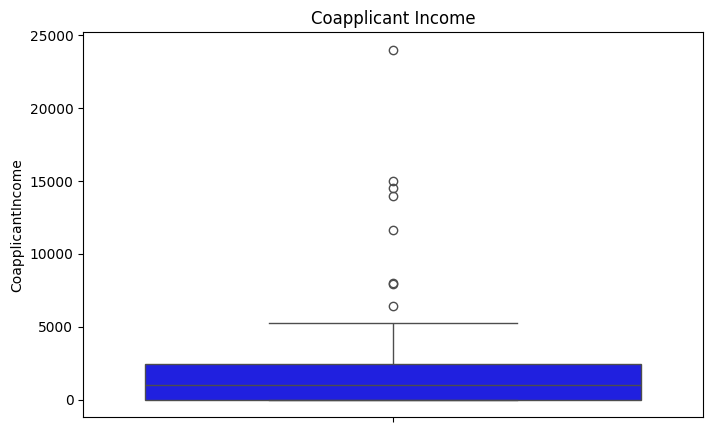

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(y=data["CoapplicantIncome"], color="b")
plt.title("Coapplicant Income")
plt.show()

3. Box plot of Loan Amount

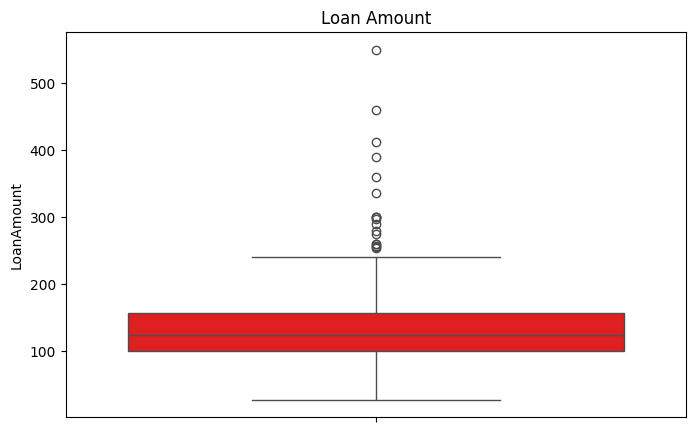

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(y=data["LoanAmount"], color="r")
plt.title("Loan Amount")
plt.show()

# Outcome of task 2.2

 All variables show outliers above the upper end, confirming the right skew
 A small number of applicants has  very high income and  loan amounts relative to the other  applicant.

# Analyze categorical variables


**2.3 Bar Charts: Visualize the frequency distributionof categorical variables**

1. Gender counts

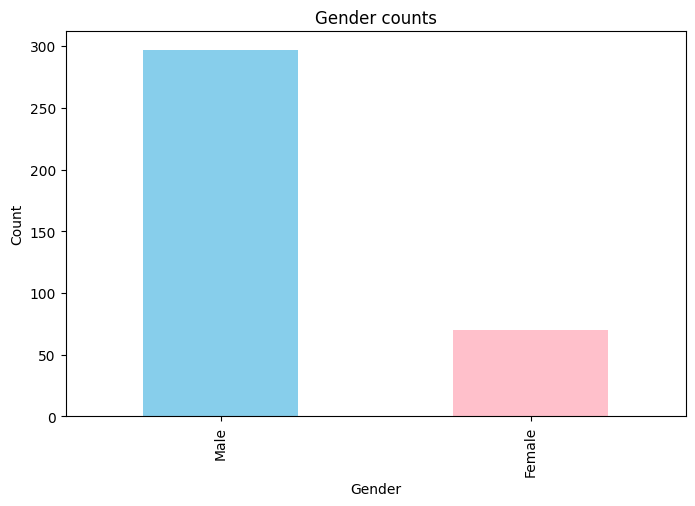

In [ ]:
plt.figure(figsize=(8,5))
data["Gender"].value_counts().plot(kind="bar", color=["skyblue", "pink"])
plt.title("Gender counts")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

2. Married counts

/tmp/ipykernel_988/1743363210.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data,x="Married",palette="bright")


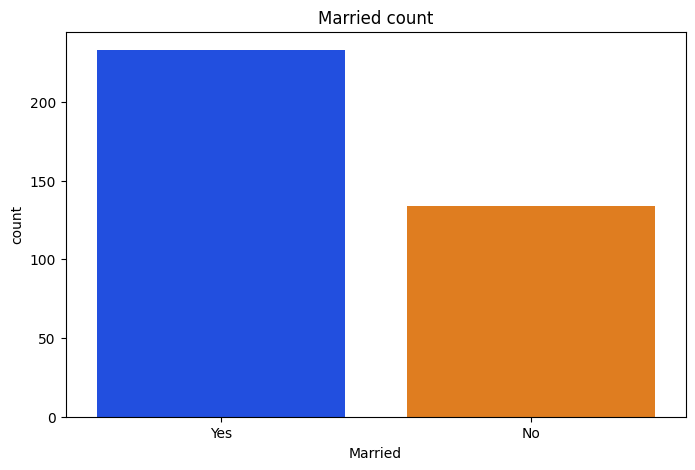

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(data,x="Married",palette="bright")
plt.title("Married count")
plt.show()

3. Dependent counts

/tmp/ipykernel_988/981259525.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data,x="Dependents",palette="muted")


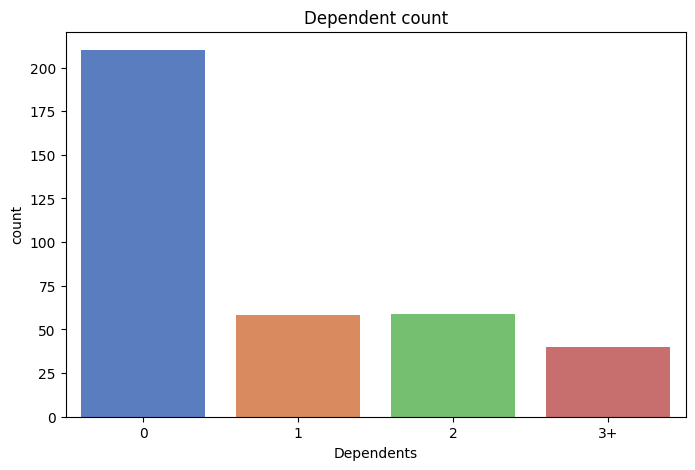

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(data,x="Dependents",palette="muted")
plt.title("Dependent count")
plt.show()

4.Education frequency

/tmp/ipykernel_988/912495468.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Education",data=data,legend=False,palette="coolwarm")


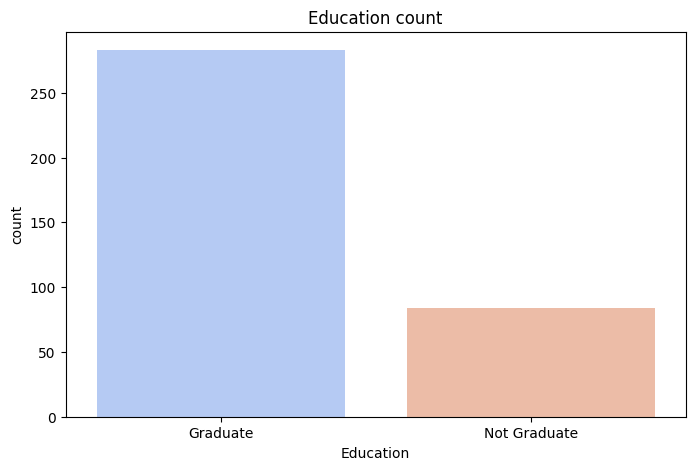

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(x="Education",data=data,legend=False,palette="coolwarm")
plt.title("Education count")
plt.show()

5. Self employed count

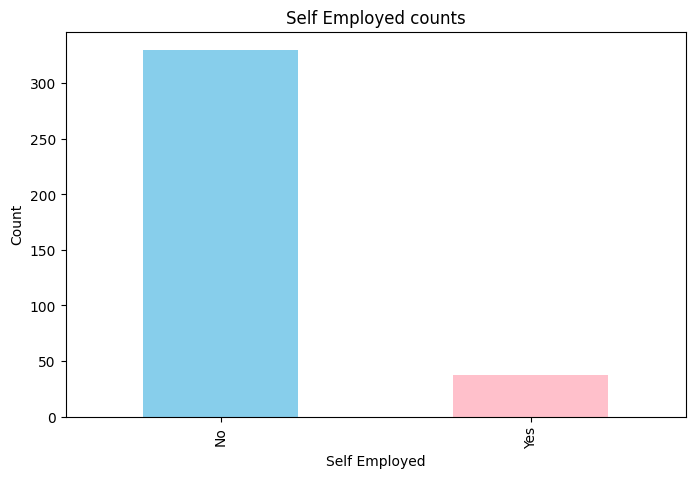

In [ ]:
plt.figure(figsize=(8,5))
data["Self_Employed"].value_counts().plot(kind='bar', color=['skyblue', 'pink'])
plt.title("Self Employed counts")
plt.xlabel("Self Employed")
plt.ylabel("Count")
plt.show()

6.Property  Area counts

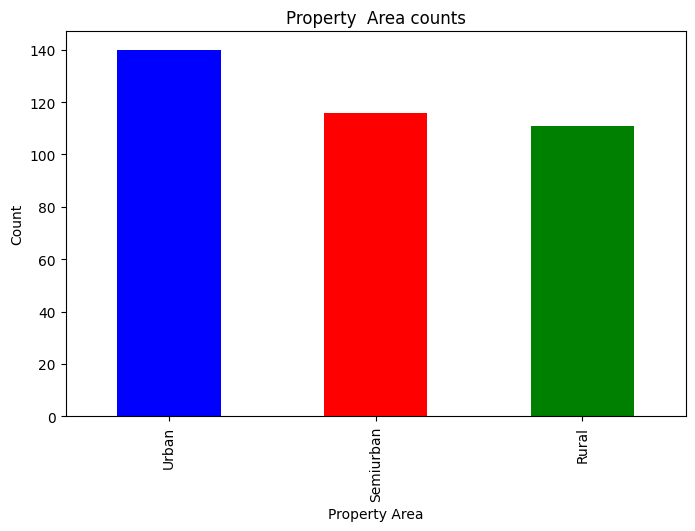

In [ ]:
plt.figure(figsize=(8,5))
data["Property_Area"].value_counts().plot(kind='bar', color=["blue", "red","green"])
plt.title("Property  Area counts")
plt.xlabel("Property Area")
plt.ylabel("Count")
plt.show()



# Insights from Task 2.3
Gender the data set has gender imbalanced male are more than female

marital status there are majorty of married people unmarried are fewer

dependents Most people have zero dependents other category are relatively low

Education level there are majority of educated people

self employed are very few in data set

property area in urban category has most count other two categeory are compertively same




**2.4 Pie Charts: Represent the composition of categorical variables.**

1. Gender Count Percentage

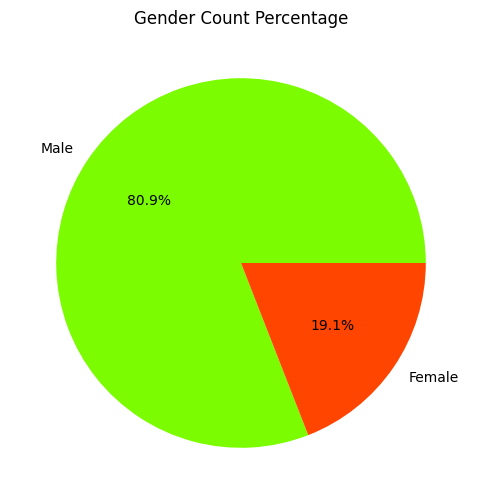

In [ ]:
plt.figure(figsize=(6, 6))
plt.pie(data["Gender"].value_counts(), labels=data["Gender"].value_counts().index,autopct="%1.1f%%",
colors={ "lawngreen",  "orangered"})
plt.title("Gender Count Percentage")
plt.show()

2. property area percentage

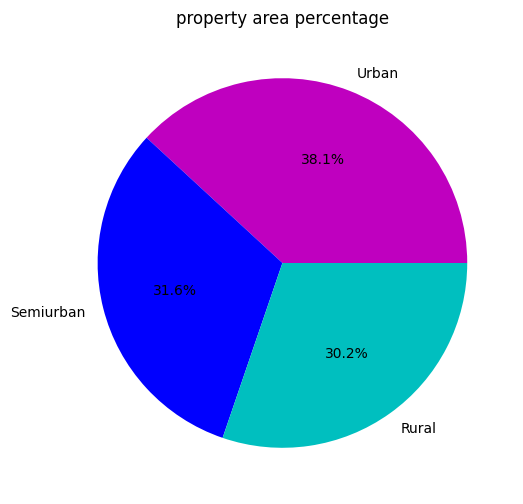

In [ ]:
plt.figure(figsize=(6, 6))
plt.pie(data["Property_Area"].value_counts(), labels=data["Property_Area"].value_counts().index,autopct="%1.1f%%",
colors={"c","m","b"})
plt.title("property area percentage")
plt.show()

3.Self Employed percentage

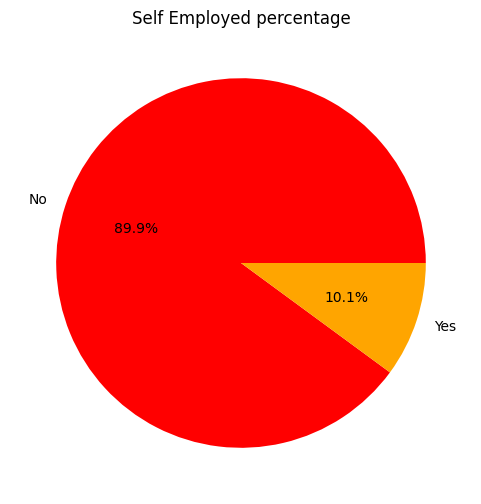

In [ ]:
plt.figure(figsize=(6, 6))
plt.pie(data["Self_Employed"].value_counts(), labels=data["Self_Employed"].value_counts().index,autopct="%1.1f%%",
colors={"orange","red"})
plt.title("Self Employed percentage")
plt.show()

4.Education percentage

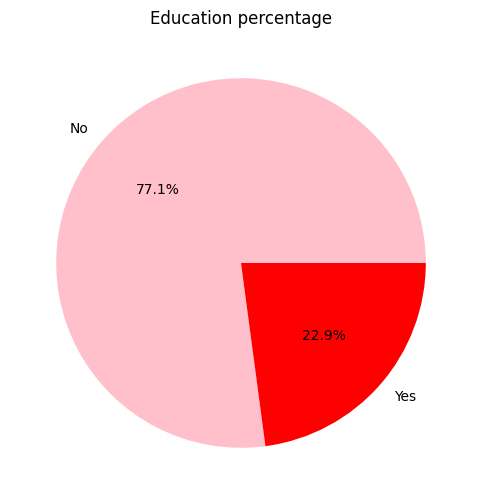

In [ ]:
plt.figure(figsize=(6, 6))
plt.pie(data["Education"].value_counts(), labels=data["Self_Employed"].value_counts().index,autopct="%1.1f%%",
colors={"pink","r"})
plt.title("Education percentage")
plt.show()

# Task 3 Bivariate Analysis

**3.1 Create scatter plots to explore relationships between pairs of numeric variables.**

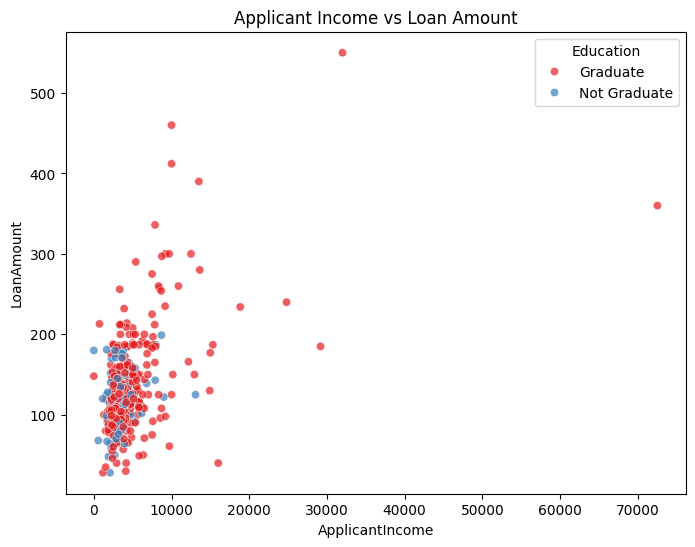

In [ ]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=data, x="ApplicantIncome", y="LoanAmount",hue="Education", alpha=0.7, palette="Set1")
plt.title("Applicant Income vs Loan Amount")
plt.show()

insights a vast majority of applicant under 10000

applicant have income more than 20000 are ver few

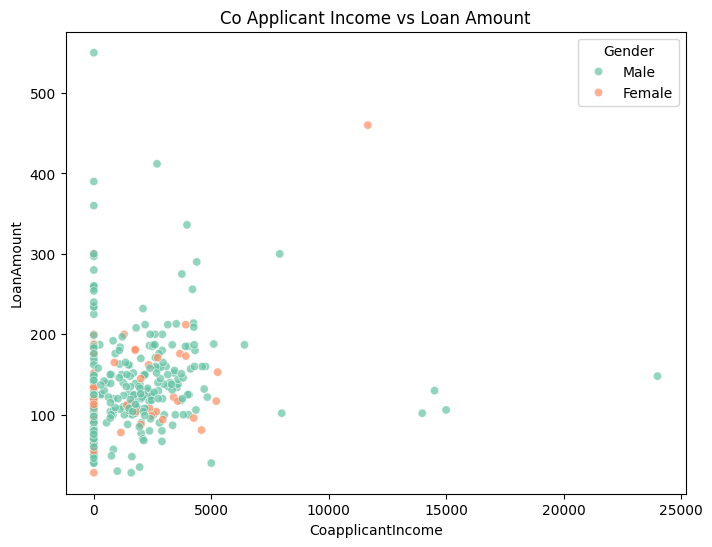

In [ ]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=data, x="CoapplicantIncome", y="LoanAmount",hue="Gender", alpha=0.7, palette="Set2")
plt.title("Co Applicant Income vs Loan Amount")
plt.show()

female co applicant income lies under 5000 only few male applicant have income more that 5000  

**3.2 Use pair plots (scatter matrix) to visualize interactions between multiple numeric variables simultaneously**

**Pair plot of numerical variables**

<Figure size 1500x1000 with 0 Axes>

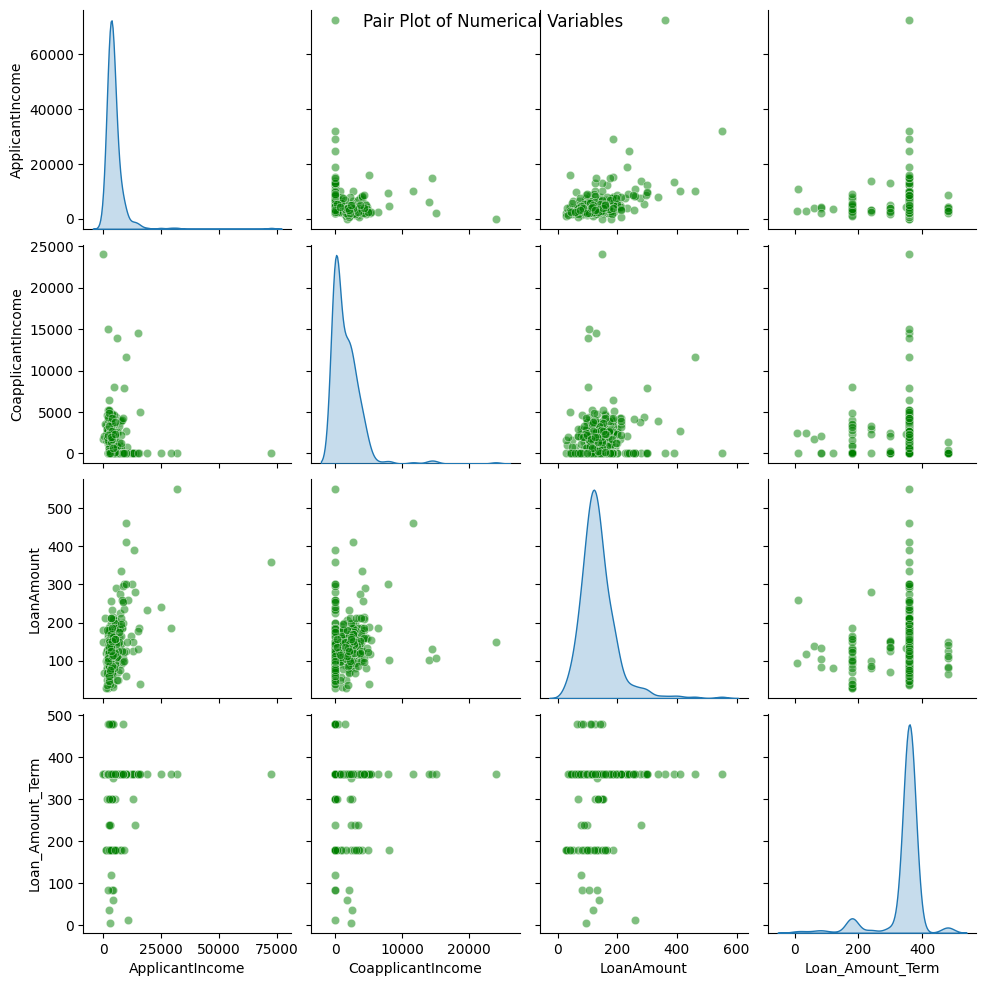

In [ ]:
num_var = data[["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term"]]
plt.figure(figsize=(15, 10))
sns.pairplot(num_var, diag_kind='kde', plot_kws={"alpha": 0.5, "color": "green"})
plt.suptitle("Pair Plot of Numerical Variables")
plt.show()




ApplicantIncome vs. LoanAmount: Positive correlation. As applicant income increases, the maximum loan amount requested generally tends to increase.

CoapplicantIncome vs. LoanAmount: Weak positive relationship. Higher coapplicant incomes show a slight baseline increase in the loan amounts requested.

Income vs. Income: Virtually no correlation exists between ApplicantIncome and CoapplicantIncome.

High-earning applicants do not necessarily have high-earning coapplicants.

Loan_Amount_Term Relationships: plots against this variable form distinct horizontal and vertical lines rather than continuous.

**3.3 Investigate the relationship between categorical and numeric variables using boxplots or violin plots.**

**1.Gender vs Credit History**

Text(0, 0.5, 'Count')

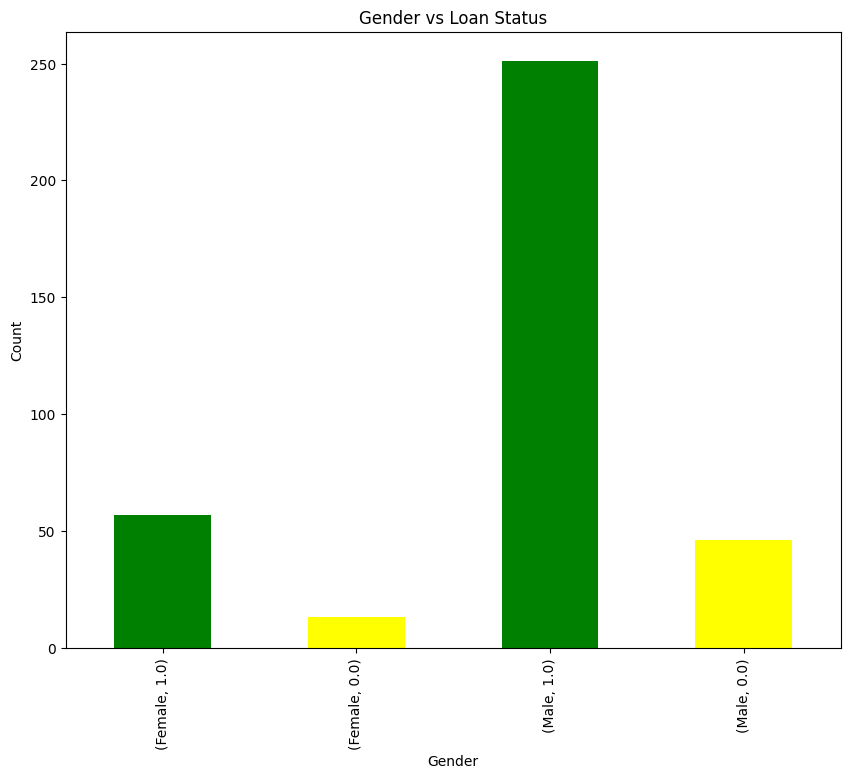

In [ ]:
plt.figure(figsize=(10,8))
data.groupby("Gender")["Credit_History"].value_counts().plot(kind="bar", stacked=True,color={"green","Yellow"})
plt.title("Gender vs Credit History")
plt.title("Gender vs Loan Status")
plt.xlabel("Gender")
plt.ylabel("Count")

Male have more success in loan credit than female

**2. Gender Vs loan amount on education qualification**

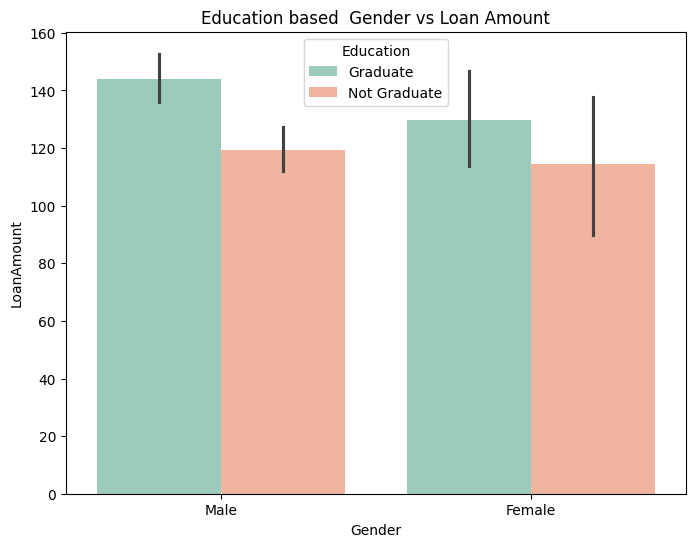

In [ ]:
plt.figure(figsize=(8,6))
sns.barplot(data=data, x="Gender", y="LoanAmount",hue="Education", alpha=0.7, palette="Set2")
plt.title("Education based  Gender vs Loan Amount")
plt.show()

Educated male in data have high percentage of loan amount

**3. loan amount vs property area**

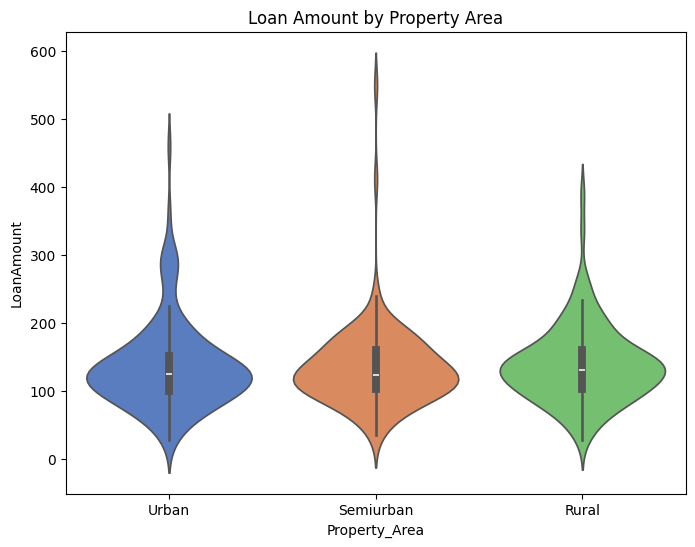

In [ ]:
plt.figure(figsize=(8,6))
sns.violinplot(data=df, x="Property_Area", y="LoanAmount",  palette="muted", hue="Property_Area", legend=())
plt.title("Loan Amount by Property Area")
plt.show()

Urban have a loan amount tends to 300

semi urban have a high tail around 600

rular have a wide belly thats tends to be lies smaller loan amount

**4.Loan Amount  by self employed**

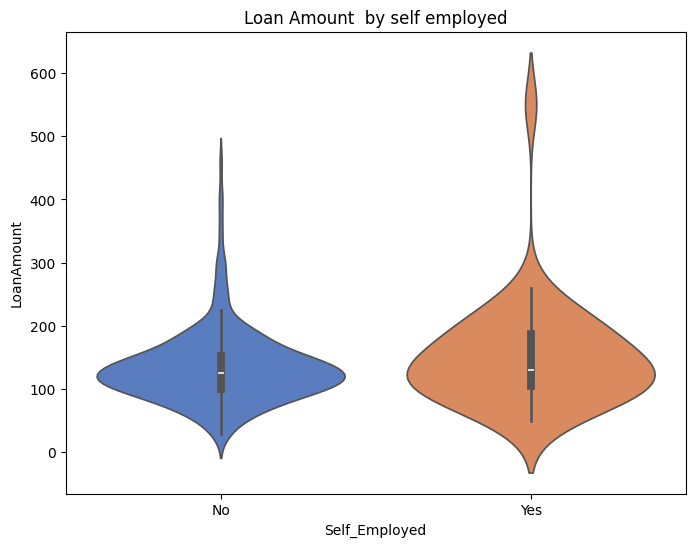

In [ ]:
plt.figure(figsize=(8,6))
sns.violinplot(data=df, x="Self_Employed", y="LoanAmount",  palette="muted", hue="Self_Employed", legend=False)
plt.title("Loan Amount  by self employed")
plt.show()

Self employed have a high percentage in loan amount tail tends to 600

**5.box plot of Applicant Income by Education**

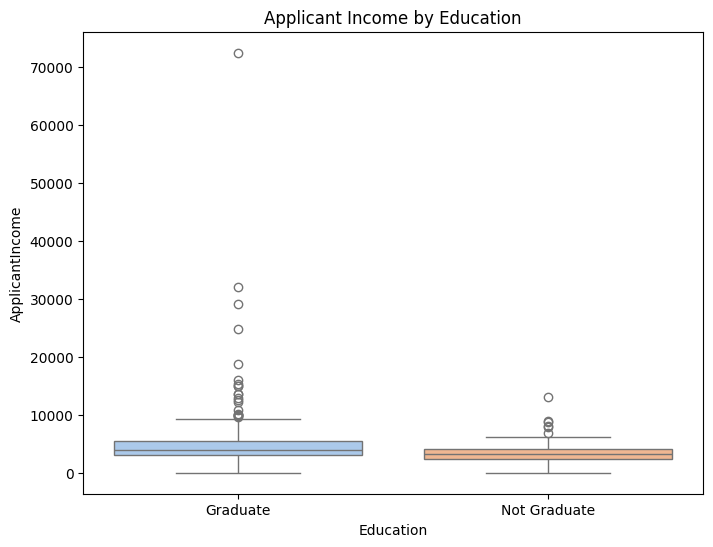

In [ ]:
plt.figure(figsize=(8,6))
sns.boxplot(data=df, x="Education", y="ApplicantIncome",  palette="pastel", hue="Education", legend=False)
plt.title("Applicant Income by Education")
plt.show()

6.box plot of Applicant Income by Marital status

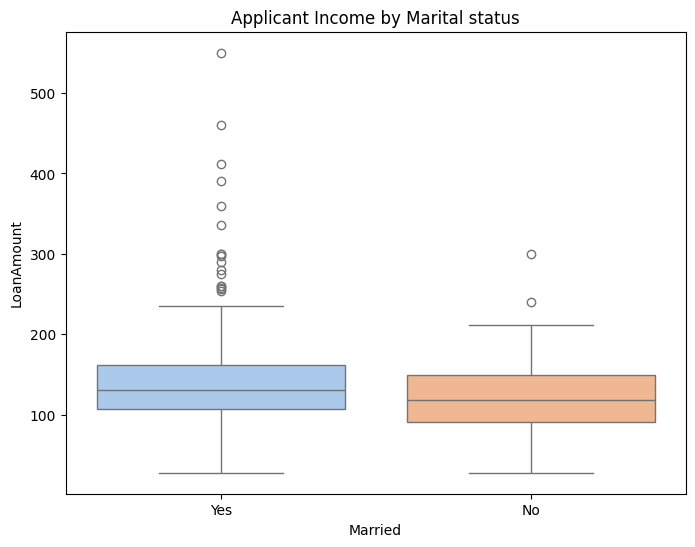

In [ ]:
plt.figure(figsize=(8,6))
sns.boxplot(data=df, x="Married", y="LoanAmount",  palette="pastel", hue="Married", legend=False)
plt.title("Applicant Income by Marital status")
plt.show()

# Task 4  Multivariate Analysis

**4.1 Perform a correlation analysis to identifyrelationships between numeric variables.**

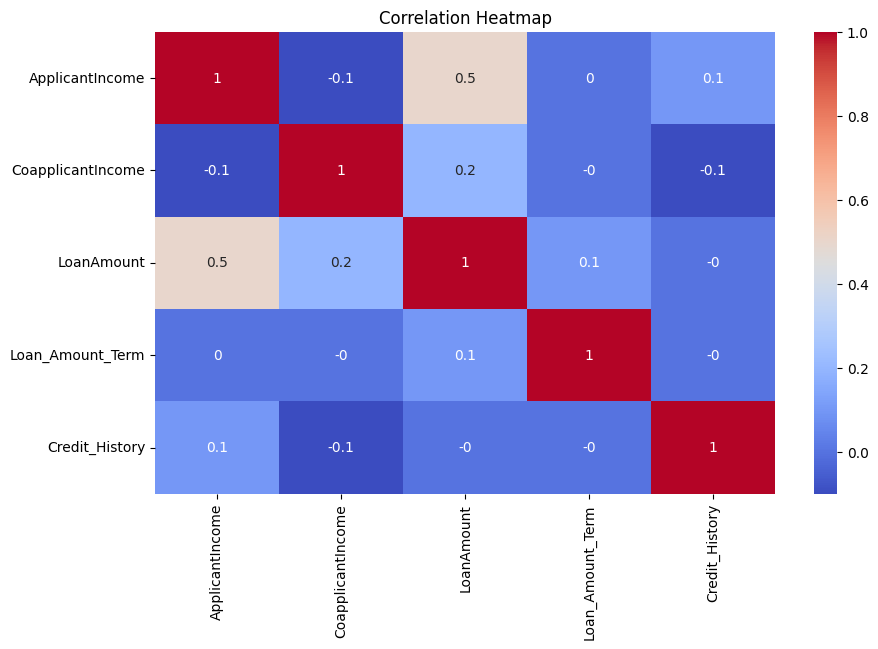

In [ ]:
num_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']

plt.figure(figsize=(10,6))
sns.heatmap(data[num_cols].corr().round(1),annot=True,cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

Strongest Relationships

Applicant Income and Loan Amount (0.5): This is the strongest positive correlation in the dataset. It indicates that applicants with higher individual incomes generally apply for larger loan amounts.

Moderate and Weak Relationships

Coapplicant Income and Loan Amount (0.2): There is a weak positive correlation here.

4.2 Create a stacked bar chart to show the distribution of categorical variables across multiple categories.

<Figure size 1000x600 with 0 Axes>

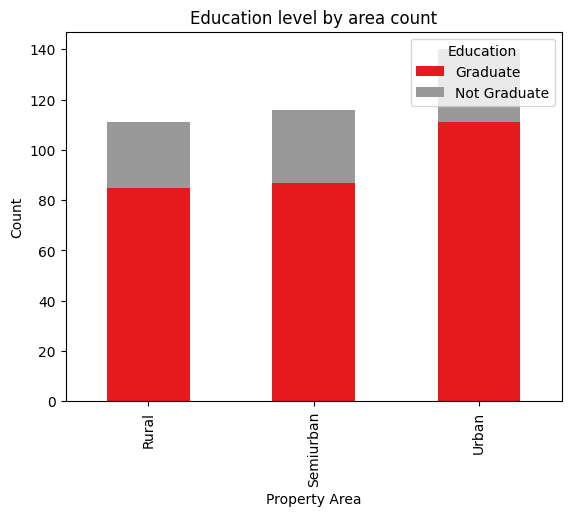

In [ ]:
stacked_data = pd.crosstab(data["Property_Area"], data["Education"])
stacked_data_pct = stacked_data.div(stacked_data.sum(axis=1), axis=0) * 100

plt.figure(figsize=(10, 6))
stacked_data.plot(kind='bar', stacked=True, colormap='Set1')
plt.title("Education level by area count")
plt.xlabel("Property Area")
plt.ylabel("Count")
plt.legend(title="Education", loc="upper right")
plt.show()



<Figure size 1200x800 with 0 Axes>

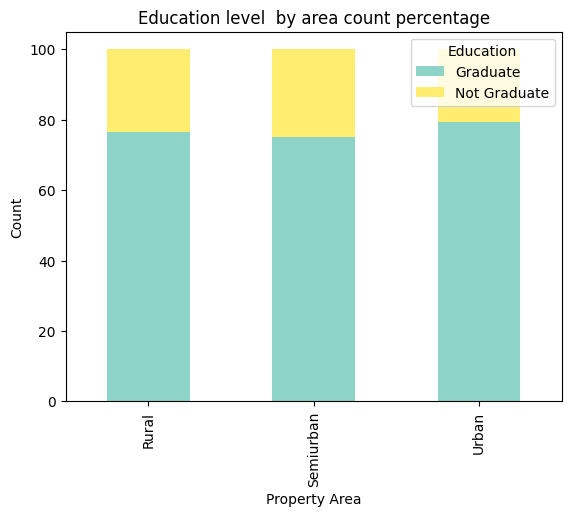

In [ ]:
plt.figure(figsize=(12, 8))
stacked_data_pct.plot(kind='bar', stacked=True, colormap='Set3')
plt.title("Education level  by area count percentage")
plt.xlabel("Property Area")
plt.ylabel("Count")
plt.legend(title="Education", loc="upper right")
plt.show()

Summary of Insights

ApplicantIncome, CoapplicantIncome, and LoanAmount are all right-skewed with a long tail of high-value outliers

medians are more representative than means for these fields.


The typical applicant is male, married, educated , not self-employed, and has no dependents.


ApplicantIncome is the strongest  correlation with LoanAmount

co-applicant income  weak correlation with loan amount.

educated have  higher incomes on average than non-educated.

 Urban applicants have more number then  Semiurban and Rural applicants


In [ ]:
data.to_csv("cleaned_loan_approval.csv",index=False)

In [ ]:
from google.colab import files
files.download("cleaned_loan_approval.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>